In [4]:
# 1. Import required libraries
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Flatten

In [10]:
# 2. Load MNIST data
train_data = pd.read_csv("fashion-mnist_train.csv")
test_data = pd.read_csv("fashion-mnist_test.csv")

In [13]:
# 3. Separate features and labels
X_train = train_data.drop("label", axis=1)
Y_train = train_data["label"]

X_test = test_data.drop("label", axis=1)
Y_test = test_data["label"]

In [14]:
# 4. Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

In [17]:
# 5. Build FNN
model = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

In [18]:
# 6. Compile the model
model.compile(
    optimizer='adam',
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [19]:
# 7. Display model architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# 8. Train the model
history = model.fit(
    X_train,
    Y_train,
    epochs = 10,
    batch_size = 128,
    validation_split=0.1
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6739 - loss: 0.9370 - val_accuracy: 0.8023 - val_loss: nan
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8020 - loss: 0.5658 - val_accuracy: 0.8262 - val_loss: nan
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8227 - loss: 0.4969 - val_accuracy: 0.8283 - val_loss: nan
Epoch 4/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.8417 - loss: 0.4506 - val_accuracy: 0.8487 - val_loss: nan
Epoch 5/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8476 - loss: 0.4244 - val_accuracy: 0.8487 - val_loss: nan
Epoch 6/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8553 - loss: 0.4011 - val_accuracy: 0.8522 - val_loss: nan
Epoch 7/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8588 - loss: 0.3843 - val_accuracy: 0.8515 - val_loss: nan
Epoch 8/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8641 - loss: 0.3669 - val_accuracy: 0.8600 - val_loss: na

In [22]:
# 9. Evaluate the model
test_loss, test_accuracy = model.evaluate(X_test, Y_test)

296/296 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8626 - loss: nan


In [23]:
print("Test loss : ", test_loss)
print("Test accuracy : ", test_accuracy)

Test loss :  nan
Test accuracy :  0.8625501990318298


In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

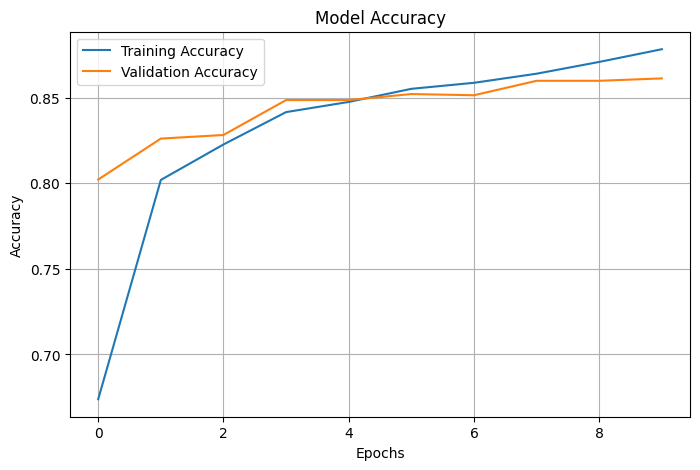

In [69]:
# Model Accuracy Graph

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

plt.show()

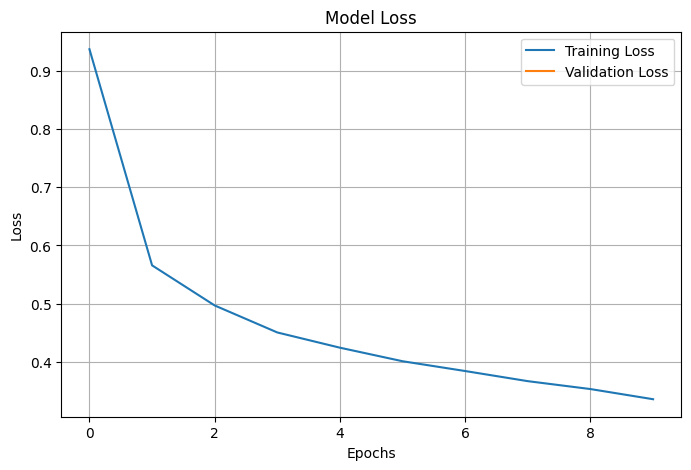

In [70]:
# Model Loss Graph

plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.show()

296/296 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


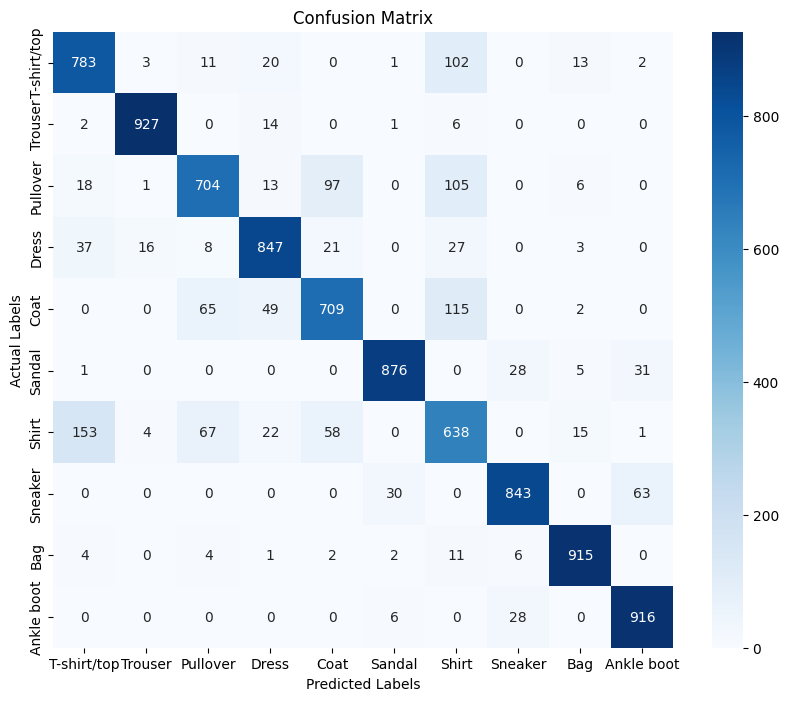

In [76]:
# Predict all test images
predictions = model.predict(X_test)

# Get predicted class labels
predicted_labels = np.argmax(predictions, axis=1)

# Generate confusion matrix
cm = confusion_matrix(Y_test, predicted_labels)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")
plt.show()

Random Index: 8337
Actual Label: 7
Predicted Label: 7


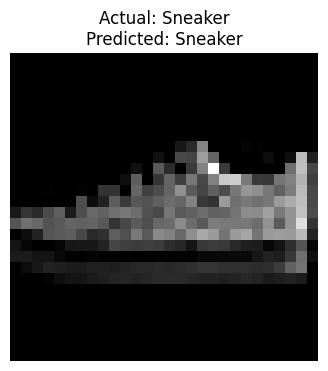

In [81]:
# Select a random image index
random_index = np.random.randint(0, len(X_test))

# Predict the selected image
random_image = X_test.iloc[random_index]
prediction = model.predict(
    random_image.values.reshape(1, 784),
    verbose=0
)

predicted_label = np.argmax(prediction)

# Display actual and predicted labels
print("Random Index:", random_index)
print("Actual Label:", Y_test.iloc[random_index])
print("Predicted Label:", predicted_label)

# Display the random image
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

plt.figure(figsize=(4, 4))

plt.imshow(random_image.values.reshape(28, 28), cmap='gray')
plt.title("Actual: " + class_names[Y_test.iloc[random_index]] +
          "\nPredicted: " + class_names[predicted_label])
plt.axis('off')
plt.show()